# 笔记 5：新的论文叙事——流行的回报曲线如何决定市场结构

这份笔记确定论文的新叙事逻辑：主张是什么、由哪些结果支撑、每个结果的可靠程度，以及正文与附录的分配。它取代笔记 4 中第 6、7 章的安排；笔记 4 的第 5 章内容大部分保留，作为新叙事的基础。

## 0.1 一句话主张
> 开发者选择基础模型时几乎只看流行，但流行的回报是 **S 形**的：最初的少数采纳者让一个模型"起飞"，此后再多的采纳几乎不再增加吸引力。正是这个形状——而不是流行的重要程度——使市场在快速增长中保持多元，并且越长越分散。文献默认的对数线性设定恰好把市场放在"临界点"上，因而系统性地夸大了锁定和赢家通吃。

## 0.2 为什么要换叙事
- **原叙事**（笔记 4）的结论是"流行解释 92% 的选择，其中累积优势只占四分之一"。它成立，但属于"valid but boring"。
- **探索中出现了一个谜题：** 用同一份数据估计的模型，在逐步预测时几乎完全复现真实网络；一旦让模型自己的选择反馈回网络状态，网络就过度集中，并且越长越集中，而真实市场越长越分散。
- **逐一排除之后，唯一同时满足三条标准的解释是函数形式**，即流行回报曲线的形状（§2.3 的标准，§3 的检验）。
- 这把论文从"流行有多重要"转向"流行的回报是什么形状、这个形状如何决定市场结构"，有一个可估计的核心参数，有理论框架，也有政策含义。

## 0.3 口径
- **样本：** 首次采纳（plan A），(d+1) PPS 候选集，五组特征，按选择加权；与笔记 4 的主规格 P5 相同。
- **小规模结果：** 来自 10%、25%、50% 的作者子样本（各 2 个种子）和截止到 2024-03、2024-09 的生长。按约定，结论在各档之间稳定才写进笔记。
- **全量结果：** 主规格的三个连接核（线性、分段、分段 + 枢纽 FE）在全样本上估计，并生长到全期、5 个种子（§4.3）。
- **代码：** `scripts/v2_mech.py`（各项检验）、`scripts/v2_grow.py`（带反馈的生长）。所有表在 `results/tables/v2/v2m_*`。重跑本笔记：`sbatch slurm/nb.sbatch notebooks/note5_narrative.ipynb`。

In [1]:
import os, sys, glob, pickle, warnings
os.environ.setdefault("ACMEC_DATA_ROOT", "/net/spaces/jevans/klab/caroyf/data/ACMEC")
sys.path.insert(0, "/home/caroyf/myproject/ACMEC/src")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
warnings.filterwarnings("ignore")
TAB = "/net/spaces/jevans/klab/caroyf/data/ACMEC/results/tables/v2"
C = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]; GRAY = "#8a8984"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6, "font.size": 9})
pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
show = display
tab = lambda name: pd.read_csv(f"{TAB}/{name}.csv")

## 1. 谜题：流行主导每一次选择，市场却越长越分散

**事实一（第 5 章）：** 流行解释了选择似然增益的 91.6%，需求匹配 5.2%，通用质量几乎为零。

**事实二：** 真实网络的头部集中随时间下降。同一批首次采纳，截止到不同时点：

| 截止 | 真实网络 top-10 份额 |
|---|---|
| 2024-03 | 0.326 |
| 2024-09 | 0.284 |
| 全期 | 0.219 |

**事实三：** 用同一份数据估计的标准模型（对数线性的流行项），让它的选择反馈回网络后，集中随时间**上升**，全期 top-10 份额约 0.39，远超种子间的波动。

**谜题：** 如果开发者几乎只看流行，为什么市场没有越来越集中？为什么用他们的选择估计出的模型却会？

下表给出机制探索中所有生长网络与真实网络的比较（同一批选择、同一截止时点）。

In [2]:
M = tab("v2m_mech_nets")
keep = ["REAL", "NP_LIN", "NP_HINGE", "NP_STEPF"]
G = (M[M.network.isin(keep)].groupby(["until", "network"])
     [["top10", "eff_parents", "gini", "tail_alpha", "turnover", "org_turnover", "overlap_real_top10"]].mean())
G["top10_range_over_seeds"] = M[M.network.isin(keep)].groupby(["until", "network"]).top10.agg(lambda x: x.max() - x.min())
show(G.round(3))

top10  eff_parents   gini  tail_alpha  turnover  org_turnover  overlap_real_top10  top10_range_over_seeds
until   network                                                                                                            
2024-03 NP_HINGE  0.317      323.687  0.805       1.803     0.706         0.562                0.10                   0.001
        NP_LIN    0.272      667.963  0.716       2.214     0.788         0.444                0.20                   0.080
        NP_STEPF  0.265      426.132  0.789       1.782     0.756         0.556                0.15                   0.049
        REAL      0.326      303.201  0.808       1.735     0.475         0.250                1.00                   0.000
2024-09 NP_HINGE  0.291      424.470  0.833       1.822     0.630         0.500                0.10                   0.005
        NP_LIN    0.320      623.050  0.773       2.156     0.675         0.385                0.15                   0.038
        NP_STEPF  0.246      602.723  0.816       1.792     0.670         0.480                0.15                   0.040
        REAL      0.284      491.979  0.818       1.769     0.460         0.230                1.00                   0.000
full    REAL      0.219      836.675  0.854       1.655     0.479         0.236                1.00                   0.000

**怎么读：** `NP_LIN` 是线性设定，`NP_HINGE` 是分段线性，`NP_STEPF` 是细分箱，三者在同一个 50% 作者子样本上估计。
- 线性设定的头部集中随时间上升（0.27 → 0.32），尾部偏薄（尾指数约 2.2），Gini 偏低。
- 两种灵活设定都复现了真实的分布形状（Gini 约 0.81–0.83，尾指数约 1.8），以及集中随时间**下降**的方向。
- 头部集中的水平：分段线性接近真实，细分箱略低（约 0.04–0.06），差异来自最顶端的形状（§3.5）。
- 机构层面的更替率（`org_turnover`）三种设定都高于真实，这是新叙事尚未解释的部分（§8）。

## 2. 方法上的关键区分：一步预测与闭环生长

### 2.1 两种模拟
两者都保留真实的事件序列（谁、何时、在哪个模态第一次采纳父模型），只重新抽取"选哪个父模型"。

- **(a) 回放（开环）：** 每次选择的候选集和特征都取自**真实**历史；抽中的父模型不写回网络。回放网络 $=\sum_k P(\cdot\mid \text{真实 }s_{t_k})$。它检验条件分布 $P(\cdot\mid s)$ 是否正确，这正是最大似然的目标。
- **(b) 生长（闭环）：** 抽中的父模型写回网络，下一次选择的候选集和全部特征都按**模拟**状态重算。网络是"选择 → 状态 → 选择"这个动态系统的路径。

### 2.2 为什么只有 (b) 能检验"生成"
- $t_k$ 时刻的集中几乎完全存储在状态 $s_{t_k}$ 里（谁已有很多采纳者、谁近期很热），而状态是过往选择累积的结果。
- 回放把状态取自现实，任何给 degree 较大权重的模型都会继承现实的集中：只用流行（0.225）、不含 FE 的完整模型（0.212）、含 FE 的完整模型（0.222）都接近真实的 0.219。所以回放只是一步校准检验。
- 类比：时间序列模型可以一步预测很准，长期方差却完全错误。网络集中是长期性质。
- **对第 7 章的含义：** 平台反事实（匹配 ×2 时集中不变）是在回放中算的，只说明一步之内不变，需要在 (b) 中重做。

### 2.3 判断一个解释是否合格的三条标准
网络差距真实存在，必须解释。但只用网络矩去校准模型（比如加一个专门消除差距的项）会掩盖问题：只用流行估计的模型选择拟合更差，生成的网络反而更接近真实，正是两个误差抵消的例子。一个合格的解释必须：
1. 从选择数据估计，而不是对着网络矩校准；
2. 不让样本外的选择拟合变差；
3. 在闭环中缩小差距。

### 2.4 为什么函数形式不同于遗漏变量
- 遗漏变量的集合无界且不可观测，永远无法确认找全。
- 函数形式是**已观测变量**的一维函数，可以非参数地估计（sieve：逐步加细的近似）；继续加细而结论不变，就说明形状已经找对。这是一个可检验的收敛标准（§3.1）。

## 3. 回报曲线：S 形，而不是幂律

**对象：** 选择概率 $P(l)\propto\exp\big(f(d_l)+g(r_l)+\theta^\top x_l-\log\pi_l\big)$，其中 $d$ 是累积采纳数，$r$ 是近 30 天采纳数。流行部分等价于网络形成中的**连接核** $A(d,r)=e^{f(d)+g(r)}$。
- **线性设定：** $f(d)=\beta_0\mathbb 1[d>0]+\alpha\log d$，即幂律核 $A\propto d^{\alpha}$（优先连接族）。
- **分段线性：** $\log d$ 在 $d=10,100,1000$ 设节点，$\log(1+r)$ 在 $r=3,10,30,100$ 设节点。
- **细分箱：** degree 11 个箱、近期采纳 9 个箱，每箱一个参数。

### 3.1 sieve 收敛：非参数形状

,model,frac,seed,k,LR_vs_first,hold_gain
0,linear,0.10,0,26,0.000,6.692
1,steps_coarse,0.10,0,32,-15062.164,5.967
2,steps_fine,0.10,0,44,1178.107,6.720
3,hinge,0.10,0,33,1204.737,6.746
4,linear,0.10,1,26,0.000,6.873
5,steps_coarse,0.10,1,32,-17596.971,6.105
6,steps_fine,0.10,1,44,2099.830,6.875
7,hinge,0.10,1,33,2052.959,6.910
8,linear,0.25,0,26,0.000,6.780
9,steps_coarse,0.25,0,32,-43133.018,6.066


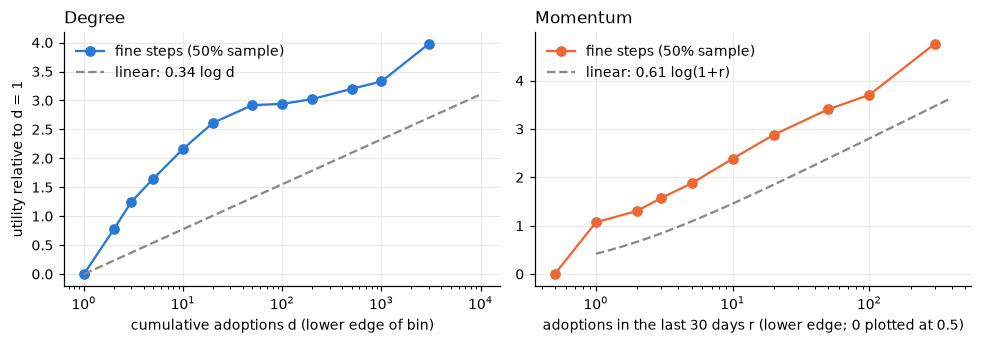

In [3]:
N = tab("v2m_shape_np")
show(N[["model", "frac", "seed", "k", "LR_vs_first", "hold_gain"]].round(3))
F = N[N.model == "steps_fine"]
dcols = sorted([c for c in F.columns if c.startswith("b_d_bin")], key=lambda c: int(c.split("_")[-1]))
rcols = sorted([c for c in F.columns if c.startswith("b_r_bin")], key=lambda c: int(c.split("_")[-1]))
F50 = F[F.frac == 0.5]
fig, ax = plt.subplots(1, 2, figsize=(9, 3.2))
xd = [1] + [int(c.split("_")[-1]) for c in dcols]
yd = [0] + list(F50[dcols].mean())
ax[0].plot(xd, yd, "o-", color=C[0], label="fine steps (50% sample)")
P = tab("v2m_sat_fit"); P = P[(P.model == "base") & (P.frac == 0.5)]
a = P.log_deg_slope_0.mean()
xx = np.logspace(0, 4, 50); ax[0].plot(xx, a * np.log(xx), "--", color=GRAY, label=f"linear: {a:.2f} log d")
ax[0].set_xscale("log"); ax[0].set_xlabel("cumulative adoptions d (lower edge of bin)"); ax[0].set_ylabel("utility relative to d = 1")
ax[0].legend(frameon=False); ax[0].set_title("Degree", loc="left")
xr = [0.5] + [int(c.split("_")[-1]) for c in rcols]
yr = [0] + list(F50[rcols].mean())
ax[1].plot(xr, yr, "o-", color=C[1], label="fine steps (50% sample)")
b = P.lrec30_slope_0.mean(); xx = np.logspace(0, 2.6, 50)
ax[1].plot(xx, b * np.log1p(xx), "--", color=GRAY, label=f"linear: {b:.2f} log(1+r)")
ax[1].set_xscale("log"); ax[1].set_xlabel("adoptions in the last 30 days r (lower edge; 0 plotted at 0.5)")
ax[1].legend(frameon=False); ax[1].set_title("Momentum", loc="left")
plt.tight_layout(); plt.show()

**怎么读：**
- 细分箱（44 个参数）与分段线性（33 个参数）的似然和留出集增益几乎相同（50% 样本上相对线性的似然比统计量约 8,400 与 8,600，留出集增益 +0.01 与 +0.04 nats），各档稳定。分段线性已经捕捉到形状。
- 粗分箱（每个变量 4 个箱）远差于线性：形状需要足够的分辨率。
- **degree：** 从 1 到 50 个采纳者效用增加约 2.9，从 50 到 1000 只增加约 0.4。线性设定低估了起步阶段，高估了头部。
- **动量：** 大致随 $\log r$ 增长，前段略凹。饱和主要发生在累积 degree 上。

### 3.2 Box-Cox 曲率：拒绝优先连接
用 $f_\lambda(d)=(d^\lambda-1)/\lambda$ 替换 $\log d$（$\lambda=0$ 即对数，也就是优先连接；$\lambda<0$ 表示有上界），近期采纳同理，用剖面似然在网格上估计。

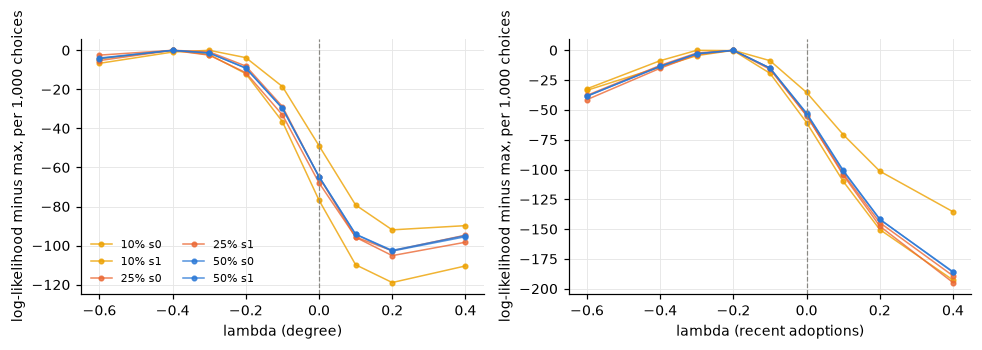

In [4]:
B = tab("v2m_shape_bc")
B["var"] = B.model.str.split().str[0]; B["lam"] = B.model.str.split("=").str[1].astype(float)
fig, ax = plt.subplots(1, 2, figsize=(9, 3))
for i, v in enumerate(["deg", "rec"]):
    for (f, s), g in B[B["var"] == v].groupby(["frac", "seed"]):
        g = g.sort_values("lam")
        ax[i].plot(g.lam, (g.ll - g.ll.max()) / g.n.iloc[0] * 1000, "o-", ms=3, lw=1,
                   color={0.1: C[3], 0.25: C[1], 0.5: C[0]}[f], alpha=0.8, label=f"{int(f*100)}% s{s}")
    ax[i].axvline(0, color=GRAY, lw=0.8, ls="--")
    ax[i].set_xlabel("lambda (" + ("degree" if v == "deg" else "recent adoptions") + ")")
    ax[i].set_ylabel("log-likelihood minus max, per 1,000 choices")
ax[0].legend(frameon=False, fontsize=7, ncol=2); plt.tight_layout(); plt.show()

**怎么读：** 累积 degree 的似然最优约 $\lambda_d=-0.4$（留出集最优约 −0.2）；$\lambda=0$ 在 50% 样本上比最优差约 3,800 个对数似然单位。近期采纳的最优约 $\lambda_r=-0.2$。两个曲率都小于 0：流行带来的效用有上界，连接核有上界。

### 3.3 排除替代解释

In [5]:
R = tab("v2m_shape_rank")
show(R[["model", "frac", "seed", "LR_vs_first", "hold_gain", "log_deg_slope_0", "log_deg_slope_1", "log_deg_slope_2",
        "log_deg_slope_3", "b_log_rank", "b_top10_mod", "b_top100_mod"]].round(3))
K = tab("v2m_shape_conf")
show(K[["model", "frac", "seed", "LR_vs_first", "hold_gain", "log_deg_slope_0", "log_deg_slope_1", "log_deg_slope_2",
        "log_deg_slope_3"]].round(3))

,model,frac,seed,LR_vs_first,hold_gain,log_deg_slope_0,log_deg_slope_1,log_deg_slope_2,log_deg_slope_3,b_log_rank,b_top10_mod,b_top100_mod
0,hinge,0.10,0,0.000,6.746,0.879,0.353,0.214,0.183,NaN,NaN,NaN
1,hinge + rank,0.10,0,110.906,6.744,0.961,0.465,0.372,0.279,0.148,0.117,-0.089
2,linear + rank,0.10,0,-834.890,6.704,0.589,0.589,0.589,0.589,0.207,-0.279,-0.115
3,hinge,0.10,1,0.000,6.910,0.928,0.376,0.094,0.226,NaN,NaN,NaN
4,hinge + rank,0.10,1,185.743,6.910,1.019,0.520,0.294,0.326,0.165,0.160,-0.185
5,linear + rank,0.10,1,-1399.328,6.887,0.634,0.634,0.634,0.634,0.239,-0.377,-0.277
6,hinge,0.25,0,0.000,6.841,0.887,0.285,0.112,0.174,NaN,NaN,NaN
7,hinge + rank,0.25,0,475.861,6.845,0.992,0.438,0.308,0.285,0.193,0.202,-0.099
8,linear + rank,0.25,0,-2963.791,6.810,0.596,0.596,0.596,0.596,0.264,-0.288,-0.167
9,hinge,0.25,1,0.000,6.606,0.831,0.376,0.113,0.216,NaN,NaN,NaN


,model,frac,seed,LR_vs_first,hold_gain,log_deg_slope_0,log_deg_slope_1,log_deg_slope_2,log_deg_slope_3
0,hinge,0.10,0,0.000,6.746,0.879,0.353,0.214,0.183
1,hinge + age shape,0.10,0,381.494,6.766,0.882,0.342,0.129,0.143
2,hinge + age shape + succession,0.10,0,624.421,6.787,0.870,0.361,0.110,0.175
3,hinge,0.10,1,0.000,6.910,0.928,0.376,0.094,0.226
4,hinge + age shape,0.10,1,502.454,6.920,0.942,0.344,-0.012,0.173
5,hinge + age shape + succession,0.10,1,817.898,6.934,0.928,0.361,-0.031,0.215
6,hinge,0.25,0,0.000,6.841,0.887,0.285,0.112,0.174
7,hinge + age shape,0.25,0,1353.682,6.863,0.894,0.261,0.004,0.130
8,hinge + age shape + succession,0.25,0,2074.261,6.880,0.882,0.281,-0.011,0.170
9,hinge,0.25,1,0.000,6.606,0.831,0.376,0.113,0.216


**怎么读：**
- **排名 vs 数量（有限注意）：** 加入模态内排名、进入前 10、进入前 100 后，似然只小幅改善，留出集没有改善；控制排名后饱和依然存在。开发者对采纳**数量**作出反应，不是对榜单位置。
- **年龄与被取代：** 加入年龄的分段形式和"被同类新版本取代"特征后，degree 在 100–1000 的斜率从约 0.12 降到约 0，饱和更强。饱和不是"老枢纽被冷落"。

### 3.4 谁在饱和：按作者类型

In [6]:
T = tab("v2m_shape_type")
cols = ["log_deg_slope_0", "log_deg_slope_1", "log_deg_slope_2", "log_deg_slope_3", "lrec30_slope_0", "lrec30_slope_4", "b_has_deg"]
show(T.groupby("model")[cols].mean().round(3).loc[["novice individuals", "experienced individuals", "organizations"]])

,log_deg_slope_0,log_deg_slope_1,log_deg_slope_2,log_deg_slope_3,lrec30_slope_0,lrec30_slope_4,b_has_deg
model,,,,,,,
novice individuals,1.017,0.459,0.441,0.265,0.931,0.473,3.882
experienced individuals,0.773,0.252,-0.156,0.057,1.459,0.458,3.335
organizations,0.480,0.095,-0.045,-0.005,1.038,0.407,2.749


**怎么读：**
- 专家（有经验的个人）和机构在 10–100 个采纳者之后几乎不再响应累积 degree；新手个人在高端仍有正斜率（0.44、0.26）。
- **这与信息瀑布的预测相反**（瀑布理论预测私人信息少的人更早饱和）；它符合私人信息精度不同的社会学习：私人信息越精确，对公共信号的依赖越早停止。专家把流行当作"有没有人用过"的门槛信号，新手把它当作连续的排序。
- **整体的饱和是构成效应：** 高端的平坦曲线来自专家和机构。由此得到一个可检验的预测：新手比例越高的时期或模态，头部的回报指数越高，集中压力越大（§8）。

### 3.5 头部：超级明星溢价还是枢纽自身的 ξ

In [7]:
show(tab("v2m_top_desc"))
TP = tab("v2m_top")
H = TP[TP.model.str.startswith("hinge")]
show(H.groupby("model")[[c for c in H.columns if "slope" in c or "kappa" in c]].mean().round(3))
S = TP[TP.model.str.startswith("steps")]
show(S.groupby("model")[[c for c in S.columns if c.startswith("b_d_bin")]].mean().round(3))

,bin,chosen,share_of_choices,distinct_parents,top5_parents_share_of_bin
0,"[1000, 3000)",13354,0.113642,40,0.386476
1,"[3000, 10000)",8982,0.076437,13,0.929971
2,"[10000, inf)",4791,0.040771,4,1.000000


,deg_slope_<10,deg_slope_10-100,deg_slope_100-1000,deg_slope_1000-3000,deg_slope_3000-10000,deg_slope_>10000,rec_slope_top,kappa_top(>10000)
model,,,,,,,,
hinge,0.874,0.370,0.088,0.380,0.613,-0.985,0.510,-0.475
hinge + hub FE,0.642,0.014,-0.154,0.019,0.481,-0.787,0.321,-0.467
"hinge, top-10 hubs dropped",0.825,0.372,0.037,0.287,-0.845,0.166,0.283,0.448


,b_d_bin_500,b_d_bin_1000,b_d_bin_3000,b_d_bin_10000
model,,,,
steps,3.253,3.380,3.946,4.198
steps + hub FE,1.457,1.288,1.725,1.483


**怎么读：**
- d≥3000 的区间只有 17 个不同的父模型（≥10000 只有 4 个），这一段的"曲线"无法从横截面识别。
- 不含 FE 时，d≥3000 有一个额外跳升；加入枢纽 FE 后消失。跳升是这几个超级枢纽自身的吸引力（ξ），不是"越流行越受欢迎"。
- **用同一枢纽随时间的变化识别（含 FE）：** 累积 degree 在 10 以上的斜率约为 0（10–100：≈0；100–1000：约 −0.17；1000–3000：≈0），只有近期动量仍有约 0.3 的斜率。
- **结论：** 头部是明确的报酬递减；超级枢纽的身份与头部集中的水平由少数模型的持久溢价决定（§6）。主设定因此把 d≥1000 合为一段，不估计无法识别的最顶端形状。

### 3.6 全量估计（主设定）
全样本（117,509 次训练首次采纳）估计的三个连接核。分段 = 节点 d=10、100、1000 与 r=3、10、30、100。

In [8]:
KF = tab("v2m_kernel_full")
show(KF[["model", "n", "ll", "hold_gain", "log_deg_slope_0", "log_deg_slope_1", "log_deg_slope_2", "log_deg_slope_3",
         "lrec30_slope_0", "lrec30_slope_1", "lrec30_slope_2", "lrec30_slope_3", "lrec30_slope_4"]].round(3))

,model,n,ll,hold_gain,log_deg_slope_0,log_deg_slope_1,log_deg_slope_2,log_deg_slope_3,lrec30_slope_0,lrec30_slope_1,lrec30_slope_2,lrec30_slope_3,lrec30_slope_4
0,K_LIN,117509,-359783.600,6.625,0.344,0.344,0.344,0.344,0.605,0.605,0.605,0.605,0.605
1,K_HINGE,117509,-351074.938,6.664,0.853,0.352,0.135,0.193,1.169,0.470,0.783,0.615,0.497
2,K_HINGE_FE,117509,-329629.260,6.685,0.624,0.008,-0.153,0.035,0.891,0.270,0.601,0.494,0.321


**怎么读（全量）：**
- **分段设定的形状与小样本一致：** degree 斜率 0.85、0.35、0.13、0.19（d<10、10–100、100–1000、>1000）；近期采纳斜率 1.17、0.47、0.78、0.62、0.50。
- **拟合：** 相对线性设定，对数似然提高约 8,700（33 对 26 个参数），留出集增益从 6.625 提高到 6.664 nats。
- **加入枢纽 FE 后：** degree 在 10 以上的斜率约为 0（0.01、−0.15、0.04），近期采纳的头部斜率 0.32。头部的报酬递减在同一枢纽内部同样成立。

## 4. 从回报曲线到市场结构

### 4.1 理论框架：广义 Pólya 罐子与有效回报指数
设某个模型在采纳流中的份额长期稳定为 $s$。它的累积采纳 $d$ 和近期采纳 $r$ 都近似与 $s$ 成正比，于是在它与其他在位者竞争时，连接核相当于

$$A\propto s^{\kappa},\qquad \kappa(s)=\frac{\partial f}{\partial\log d}+\frac{\partial g}{\partial\log r}.$$

$\kappa$ 是**有效回报指数**：份额每提高 1%，吸引力提高约 $\kappa$%。广义 Pólya 罐子与报酬递增的经典结论（Hill, Lane & Sudderth 1980；Arthur, Ermoliev & Kaniovski 1987；Arthur 1989，引用前核对）：
- $\kappa>1$：报酬递增，份额向一个赢家集中，谁赢由早期运气决定（锁定）；
- $\kappa=1$：临界，份额收敛到随机的极限，路径依赖最强；
- $\kappa<1$：报酬递减，多个模型共存，长期份额由属性决定。

再加上一个简单的上界结论：若核有上界 $A\le\bar A$，且被使用过的模型的核不低于 $a>0$，则任一模型在采纳流中的份额不超过 $\bar A/(\bar A+(N_t-1)a)$。随着被使用的模型数 $N_t$ 增长，头部份额必然下降。

**注意：** $\kappa$ 的推导是平均场近似（份额稳定、$d$ 与 $r$ 同比例变化）。论文中写成命题加闭环模拟验证，不当作严格定理。

### 4.2 估计出的 κ

In [9]:
def kappa_row(lbl, deg, rec):
    return dict(spec=lbl, deg_slope=deg, rec_slope=rec, kappa=deg + rec)
P = tab("v2m_sat_fit"); P = P[P.frac == 0.5]
base = P[P.model == "base"]; spl = P[P.model == "spline"]
TPh = TP[(TP.model == "hinge + hub FE") & (TP.frac == 0.5)]
rows = [kappa_row("linear (everywhere)", base.log_deg_slope_0.mean(), base.lrec30_slope_0.mean()),
        kappa_row("hinge, takeoff (d < 10, r < 3)", spl.log_deg_slope_0.mean(), spl.lrec30_slope_0.mean()),
        kappa_row("hinge, top (d > 1000, r > 100)", spl.log_deg_slope_3.mean(), spl.lrec30_slope_4.mean()),
        kappa_row("hinge + hub FE, top (d 1000-3000, r > 100)", TPh["deg_slope_1000-3000"].mean(), TPh.rec_slope_top.mean())]
show(pd.DataFrame(rows).round(2))

,spec,deg_slope,rec_slope,kappa
0,linear (everywhere),0.34,0.61,0.95
1,"hinge, takeoff (d < 10, r < 3)",0.85,1.15,2.00
2,"hinge, top (d > 1000, r > 100)",0.20,0.51,0.70
3,"hinge + hub FE, top (d 1000-3000, r > 100)",0.02,0.30,0.32


**怎么读**（上表为 50% 样本；全量估计给出相同结论）：

| 设定（全样本） | 起飞阶段 κ（d<10, r<3） | 头部 κ（d>1000, r>100） |
|---|---|---|
| 线性 | 0.34 + 0.61 = 0.95 | 0.95 |
| 分段 | 0.85 + 1.17 = 2.02 | 0.19 + 0.50 = 0.69 |
| 分段 + 枢纽 FE | 0.62 + 0.89 = 1.51 | 0.04 + 0.32 = 0.36 |

- **线性设定：** $\kappa$ 处处约 0.95，接近临界值 1。
- **灵活设定：** 起飞阶段 $\kappa$ 约 1.5–2（报酬递增），头部约 0.4–0.7（报酬递减）。
- **真实的回报曲线是 S 形：** 能否起飞高度自我强化，起飞之后报酬递减。

### 4.3 这个框架统一解释了此前的零散发现

| 现象 | 解释 |
|---|---|
| 线性模型在闭环中过度集中，且集中随时间上升 | $\kappa\approx0.95$ 接近临界，反馈不断累积 |
| 真实市场越长越分散 | 头部 $\kappa<1$，并且新模型不断进入，头部份额被稀释 |
| 线性模型的赢家在各模拟世界间几乎随机 | 接近临界时路径依赖最强：全量中线性设定的不可预测性指标 U 是分段设定的约 3.4 倍（§6） |
| 流行占选择的 92%，市场却不失控 | 流行的作用集中在"起飞"，而不是"统治" |
| 专家早饱和、新手持续跟随 | 头部 $\kappa$ 取决于参与者构成 |

### 4.4 闭环验证（全量：全样本估计、生长到全期、5 个种子）

In [10]:
GR = tab("v2_grow")
show(GR[GR.network.isin(["K_LIN", "K_HINGE", "K_HINGE_FE", "EST", "EST_FE", "REAL"])][
    ["network", "top10_mean", "top10_std", "eff_parents_mean", "gini_mean", "tail_alpha_mean", "turnover_mean",
     "n_parents_mean", "n_seeds"]].round(3))

,network,top10_mean,top10_std,eff_parents_mean,gini_mean,tail_alpha_mean,turnover_mean,n_parents_mean,n_seeds
5,EST,0.395,0.049,508.875,0.833,2.075,0.499,12685.4,5
7,EST_FE,0.307,0.020,429.228,0.863,1.577,0.456,14333.0,5
8,REAL,0.219,NaN,836.675,0.854,1.655,0.479,15425.0,1
10,K_HINGE,0.233,0.055,761.286,0.860,1.747,0.494,13199.6,5
11,K_HINGE_FE,0.302,0.007,549.969,0.848,1.653,0.393,16475.8,5
12,K_LIN,0.395,0.049,508.875,0.833,2.075,0.499,12685.4,5


**怎么读（全量，5 个种子）：** `K_LIN` 与此前的 `EST` 完全相同（同一组系数，作为一致性检查）。

| 指标 | 真实 | 线性 | 分段 | 分段 + 枢纽 FE |
|---|---|---|---|---|
| top-10 份额 | 0.219 | 0.395 | **0.233**（SD 0.055） | 0.302（SD 0.007） |
| 有效父模型数 | 837 | 509 | **761** | 550 |
| Gini | 0.854 | 0.833 | **0.860** | 0.848 |
| 尾指数 | 1.66 | 2.08 | 1.75 | **1.65** |
| 季度更替率 | 0.48 | 0.50 | **0.49** | 0.39 |
| 用到的父模型数 | 15,420 | 12,690 | 13,200 | **16,480** |

- **分段设定在全期复现了真实网络：** 头部集中、有效父模型数、Gini、更替率都与真实非常接近；线性设定的过度集中（0.395）消失。这满足 §2.3 的三条标准：从选择估计、改善样本外拟合、缩小闭环差距。
- **种子间的波动没有变小**（top-10 的 SD 0.055 对 0.049），但赢家身份的不可预测性降低了（§6）。
- **加入枢纽 FE 后，头部反而偏集中**（0.30）：FE 把真实的超级枢纽钉在头部。它改善的是赢家身份和机构层面的稳定性（§6），而不是集中的水平。
- **分工：** 回报曲线决定市场结构（集中水平、分布形状、时间方向）；少数枢纽的持久溢价决定谁在头部。

## 5. 选择的构成（原第 5 章）在新叙事中的位置
原第 5 章的结果全部保留，但角色改变：它们是"流行是什么、不是什么"的基础，新叙事在此之上回答"流行的回报是什么形状"。
- **5.1 主分解**（流行 91.6%）：引出谜题的事实一。
- **5.2 流行不是隐藏的质量**（FE 上界、外部质量、同权重副本）：保留。同权重副本中只有动量起作用，与"累积 degree 在头部不起作用"（§3.5）相互印证。
- **5.3 流行的构成：** 压缩为一段。"累积优势只占四分之一"被 §3 的形状结果取代并加强：累积采纳的作用集中在前 10 个采纳者。
- **5.4 适合份额小不是假象**（一个问题加三个质疑）：保留。
- **5.5 谁跟随流行：** 与 §3.4 的类型曲线合并。

## 6. 赢家：结构可预测，身份只有部分可预测
- **ξ 的持久性：** 训练期前后两半分别估计的枢纽 FE，校正估计噪声后相关约 0.62，各档稳定（`v2m_xi`）。赢家溢价中等程度持久。
- **重演历史（全量）：**

  | 设定 | 与真实 top-10 的重合 | 各世界之间 top-10 的重合 | 不可预测性 U | 机构 top-10 季度更替率（真实 0.24） |
  |---|---|---|---|---|
  | 线性 | 0% | 9% | 4.1×10⁻⁷ | 0.35 |
  | 分段 | 14% | 14% | 1.2×10⁻⁷ | 0.40 |
  | 分段 + 枢纽 FE | 70% | 75% | 1.0×10⁻⁸ | **0.27** |

  - 分段设定的不可预测性约为线性的 1/3.4：远离临界点后，路径依赖减弱，但仅凭回报曲线仍然预测不了谁胜出。
  - 加入枢纽 FE 后，赢家身份与机构层面的稳定性都接近真实。
  - 注意这部分是循环的：FE 枢纽按真实 degree 选出。
- **叙事位置：** 报酬递增的起飞阶段带来路径依赖（谁起飞有偶然性）；头部的统治地位来自持久的身份溢价，而不是滚雪球。数据区分不了这个溢价是天生的，还是早期运气固化成的声誉，正文要坦白这一点。

In [11]:
show(tab("v2m_xi").round(3))
show(tab("v2m_rerun")[["network", "worlds", "overlap_real_top10", "overlap_between_worlds"]].round(3))

,frac,seed,hubs_both,corr,spearman,reliability_1,reliability_2,corr_noise_corrected,sd_phi_1,sd_phi_2
0,0.10,0,84,0.561,0.438,0.876,0.874,0.641,0.956,1.062
1,0.10,1,97,0.512,0.387,0.861,0.895,0.583,0.948,1.172
2,0.25,0,171,0.567,0.466,0.892,0.940,0.619,0.916,1.218
3,0.25,1,171,0.584,0.521,0.893,0.943,0.637,0.931,1.238
4,0.50,0,233,0.593,0.564,0.921,0.956,0.632,0.960,1.155
5,0.50,1,233,0.585,0.551,0.925,0.958,0.622,0.942,1.192


,network,worlds,overlap_real_top10,overlap_between_worlds
0,EST,5,0.00,0.09
1,EST_FE,5,0.52,0.63
2,K_HINGE,5,0.14,0.14
3,K_HINGE_FE,5,0.70,0.75
4,K_LIN,5,0.00,0.09
5,QF,5,0.00,0.00
6,SF,5,0.00,0.06
7,SF_CUM,5,0.18,0.27
8,SF_FE,5,0.54,0.66
9,SF_NOMOM,5,0.16,0.12


## 7. 已有探索结果的去留

| 结果 | 去向 | 理由 |
|---|---|---|
| 网络对比（回放 vs 闭环，SF / QF / EST / REAL） | **正文**，引出谜题 | 谜题的事实三 |
| 一步预测与闭环生长的区分、三条标准 | **正文方法节** | 新叙事的方法论支点 |
| 回报曲线（sieve、Box-Cox、排名、混淆） | **正文核心** | 主结果 |
| 按作者类型的曲线 | **正文** | 机制异质性，提出可检验预测 |
| 头部与 FE | 正文一段 + 附录表 | 说明主设定为何合并最顶端 |
| κ 框架 | **正文**，命题加模拟验证 | 微观到宏观的桥梁 |
| 网络层面 Shapley（匹配对集中的贡献约为其选择份额的 2 倍） | 待定：需在分段设定下重做 | 线性设定下得到，可能改变 |
| 被取代（同类新版本） | 附录或一段 | 选择层面真实存在，但在闭环中加剧集中，不是刹车 |
| 机构生态继承 | 删除 | 各档符号不一致 |
| 支撑范围检查 | 附录 | 说明闭环把累积 degree 推出数据范围约 10% |
| 平台反事实 | **第 7 章，需在闭环中重做** | 回放中的结论不能推出长期 |
| 重演历史、ξ 持久性 | 正文一小节（§6） | 赢家的可预测性 |

## 8. 风险与待做
1. **全量闭环验证**（§4.4）：已完成，分段设定在全期复现了真实网络。
2. **网络层面 Shapley 在分段设定下重做**，确认"匹配放大集中"是否成立。
3. **平台反事实在闭环中重做**：检验"干预杠杆与局部 κ 成正比"——给新模型最初曝光 vs 压低头部。
4. **构成预测：** 新手比例越高的时期或模态，集中是否越高。
5. **机构层面的稳定性：** 真实的机构 top-10 季度更替率约 0.24；分段设定约 0.40，加入枢纽 FE 后 0.27。机构稳定性主要来自持久溢价，而不是回报曲线。
6. **κ 是平均场近似：** 正文写成命题加模拟，不作严格定理。
7. **文献：** 网络科学中连接核的非参数估计（Jeong, Néda & Barabási 2003；Pham, Sheridan & Shimodaira 2015 的 PAFit；Krapivsky, Redner & Leyvraz 2000 关于核形状与网络形态的结果），以及离散选择的网络形成（Overgoor, Benson & Ugander 2019），引用前逐一核对。

## 9. 新的论文结构
1. **引言：** 谜题——流行解释 92% 的选择，市场却越长越分散；同一份数据估计的标准模型预测的却是越来越集中。答案在流行回报曲线的形状。
2. **相关文献：** 优先连接与连接核；报酬递增与锁定；社会学习与羊群；文化市场的不平等与不可预测（Salganik 等 2006）。
3. **数据：** 不变。
4. **模型与估计：** 抽样备选的条件 logit；连接核的非参数估计；一步预测与闭环生长；三条标准。
5. **选择的构成：** 原第 5 章压缩。
6. **回报曲线：** S 形、拒绝优先连接、替代解释、按作者类型的异质性、头部与 FE。
7. **从回报曲线到市场结构：** κ 框架与命题；闭环验证（水平、时间方向、尾部、路径依赖）；赢家的可预测性。
8. **含义与讨论：** 平台干预的杠杆（在闭环中验证）；对 AI 生态竞争的含义；局限。

## 10. 审稿人可能的追问

| 追问 | 回答 |
|---|---|
| 换一个函数形式不就是调参吗？ | 形状由选择数据非参数地估计，sieve 加细后收敛；选择它的是样本外的选择似然，网络只做外部验证（§2.3、§3.1）。 |
| 饱和是不是老模型被新模型替代？ | 控制年龄形式和被取代特征后，饱和更强（§3.3）。 |
| 是不是榜单展示造成的？ | 排名特征几乎不改善拟合，控制后饱和仍在（§3.3）。 |
| 头部的形状由几个模型决定，可信吗？ | 不可信，所以主设定不估计它；用 FE 识别的组内斜率显示头部报酬递减（§3.5）。 |
| κ 的推导太粗糙？ | 它是平均场近似，正文写成命题，由闭环模拟验证（§4）。 |
| 为什么不直接用网络矩估计？ | 会让一个错误的模型因为误差抵消而"拟合"网络（§2.3）。 |
| 与优先连接文献的关系？ | 文献通常把核设为幂律并估计指数；我们发现核是 S 形的，而幂律设定把市场放在临界点上，系统性地夸大锁定（§4.2）。 |